## Tải thư viện 

In [1]:
import pandas as pd
pd.set_option('display.max_columns',None)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# =========================
# 1. CẤU HÌNH
# =========================
INPUT_FILE = INPUT_FILE = r"D:\data_visualization_project\data\processed\clean_ett.parquet"

df = pd.read_parquet(INPUT_FILE)
original = df.copy(deep=True)
OUTPUT_DIR = Path("cleaning_output")
PREPROCESS_DIR = Path("preprocess data")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREPROCESS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(INPUT_FILE)
original = df.copy(deep=True)
log = []

def record(step, detail, count=None):
    log.append({
        "Buoc_xu_ly": step,
        "Chi_tiet": detail,
        "So_luong": count
    })



In [ ]:
# =========================
# 2. KIỂM TRA TỔNG QUAN
# =========================
print("Kích thước dữ liệu:", df.shape)
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])
print("\nKiểu dữ liệu:\n", df.dtypes)
print("\nThông tin dữ liệu:")
df.info()

print("\nThống kê mô tả:")
print(df.describe(include="all").T)

print("\nTỷ lệ thiếu (%):")
print((df.isna().mean() * 100).round(2))

print("\nSố dòng trùng lặp:", df.duplicated().sum())

quality_before = pd.DataFrame({
    "Kieu_du_lieu": df.dtypes.astype(str),
    "So_luong_thieu": df.isna().sum(),
    "Ty_le_thieu_%": (df.isna().mean() * 100).round(2),
    "So_gia_tri_khac_nhau": df.nunique(dropna=True)
})

#quality_before.to_csv(
#    OUTPUT_DIR / "quality_before.csv",
#    encoding="utf-8-sig"
#) lưu file csv về chất lượng dữ liệu ban đầu 



Kích thước dữ liệu: (17420, 24)
Số dòng: 17420
Số cột: 24

Kiểu dữ liệu:
 date                datetime64[ns]
HUFL                       float32
HULL                       float32
MUFL                       float32
MULL                       float32
LUFL                       float32
LULL                       float32
OT                         float32
hour                         int32
day_of_week                  int32
day                          int32
month                        int32
hour_norm                  float32
day_of_week_norm           float32
day_norm                   float32
month_norm                 float32
split                     category
HUFL_scaled                float32
HULL_scaled                float32
MUFL_scaled                float32
MULL_scaled                float32
LUFL_scaled                float32
LULL_scaled                float32
OT_scaled                  float32
dtype: object

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17

In [4]:
# =========================
# 3. KIỂM TRA ĐỊNH DẠNG
# =========================
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

for col in df.columns:
    if any(key in col.lower()
           for key in ["date", "datetime", "timestamp"]):
        converted = pd.to_datetime(df[col], errors="coerce")
        invalid = df[col].notna() & converted.isna()
        
        record(
            "Kiểm tra ngày giờ",
            f"Cột {col}: giá trị sai định dạng",
            int(invalid.sum())
        )

        df[col] = converted

print("\nKiểu dữ liệu sau kiểm tra:")
print(df.dtypes)



Kiểu dữ liệu sau kiểm tra:
date                datetime64[ns]
HUFL                       float32
HULL                       float32
MUFL                       float32
MULL                       float32
LUFL                       float32
LULL                       float32
OT                         float32
hour                         int32
day_of_week                  int32
day                          int32
month                        int32
hour_norm                  float32
day_of_week_norm           float32
day_norm                   float32
month_norm                 float32
split                     category
HUFL_scaled                float32
HULL_scaled                float32
MUFL_scaled                float32
MULL_scaled                float32
LUFL_scaled                float32
LULL_scaled                float32
OT_scaled                  float32
dtype: object


In [ ]:
# =========================
# 4. XÁC ĐỊNH GIÁ TRỊ THIẾU
# =========================
missing_report = pd.DataFrame({
    "So_luong_thieu": df.isna().sum(),
    "Ty_le_thieu_%": (df.isna().mean() * 100).round(2)
}).sort_values("Ty_le_thieu_%", ascending=False)

print("\nBáo cáo dữ liệu thiếu:")
print(missing_report)

#missing_report.to_csv(
#    OUTPUT_DIR / "missing_report.csv",
#    encoding="utf-8-sig"
#) Lưu tệp csv về báo cáo dữ liệu thiếu 

# Kiểm tra dữ liệu thiếu theo nhóm phân loại
for col in df.select_dtypes(include=["object", "category"]).columns:
    if df[col].nunique(dropna=True) <= 20:
        print(f"\nTỷ lệ thiếu theo nhóm: {col}")
        print(
            df.groupby(col, dropna=False)
            .apply(
                lambda group: group.isna().any(axis=1).mean(),
                include_groups=False
            )
        )




Báo cáo dữ liệu thiếu:
                  So_luong_thieu  Ty_le_thieu_%
date                           0            0.0
HUFL                           0            0.0
HULL                           0            0.0
MUFL                           0            0.0
MULL                           0            0.0
LUFL                           0            0.0
LULL                           0            0.0
OT                             0            0.0
hour                           0            0.0
day_of_week                    0            0.0
day                            0            0.0
month                          0            0.0
hour_norm                      0            0.0
day_of_week_norm               0            0.0
day_norm                       0            0.0
month_norm                     0            0.0
split                          0            0.0
HUFL_scaled                    0            0.0
HULL_scaled                    0            0.0
MUFL_scaled     

C:\Users\dvt\AppData\Local\Temp\ipykernel_15112\1572321189.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(col, dropna=False)


In [6]:
# =========================
# 5. XÁC ĐỊNH QUY TẮC HỢP LỆ
# =========================
# Khai báo miền giá trị theo nghiệp vụ nếu có.
# Ví dụ: VALID_RANGES = {"age": (0, 120)}
VALID_RANGES = {}

for col, (lower, upper) in VALID_RANGES.items():
    if col in df.columns:
        invalid = df[col].notna() & ~df[col].between(lower, upper)

        record(
            "Kiểm tra miền giá trị",
            f"{col} phải nằm trong [{lower}, {upper}]",
            int(invalid.sum())
        )

        print(f"{col}: {invalid.sum()} giá trị ngoài miền hợp lệ")



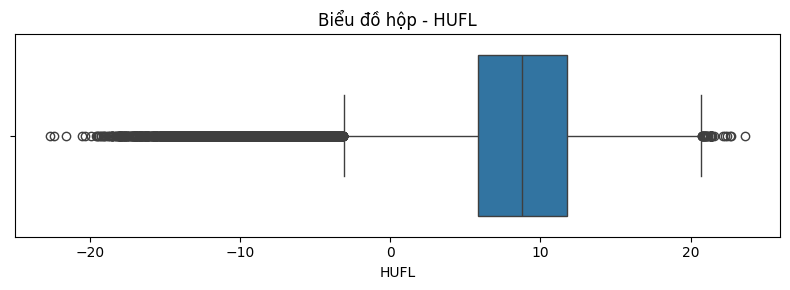

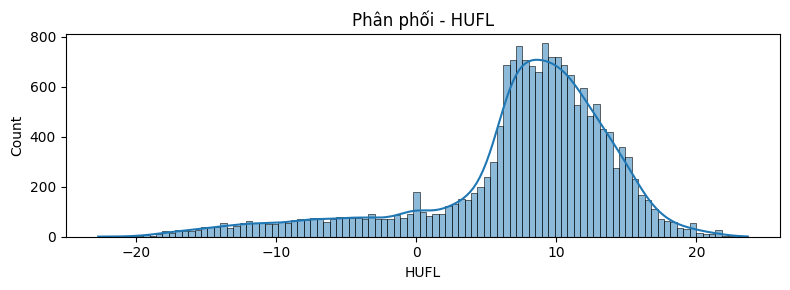

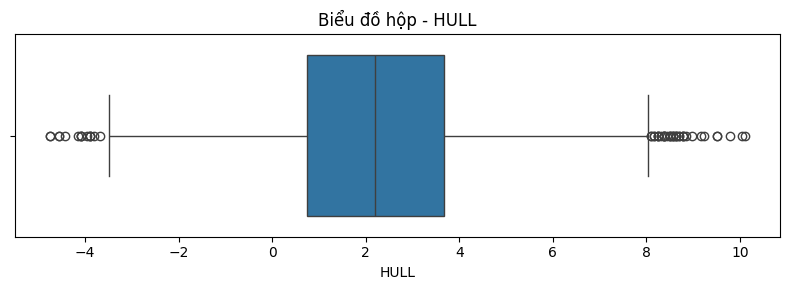

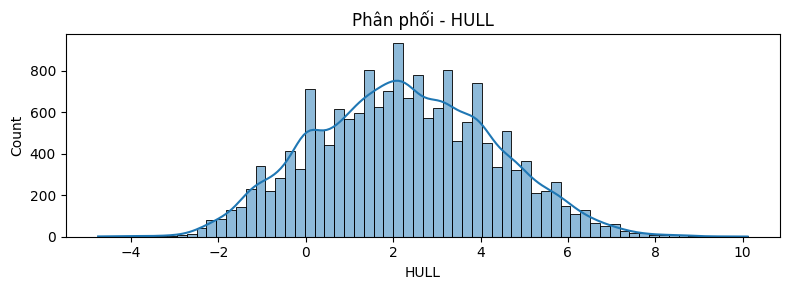

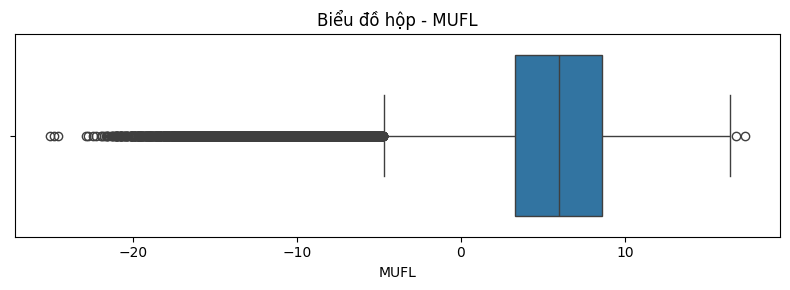

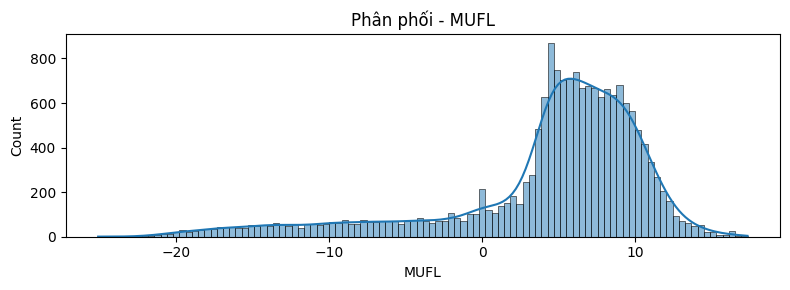

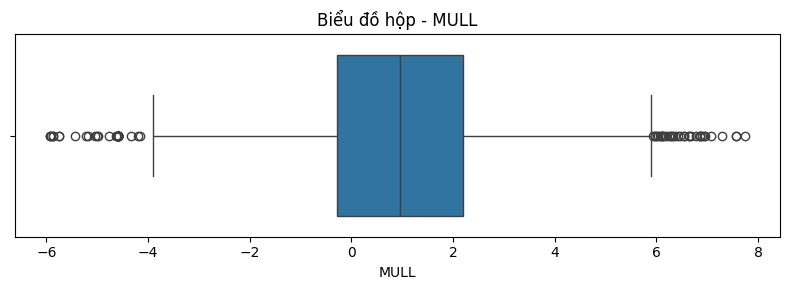

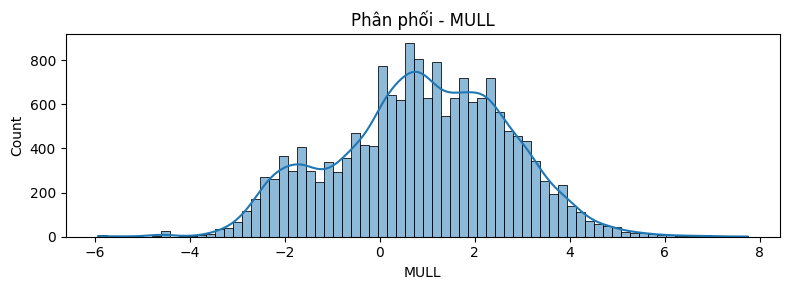

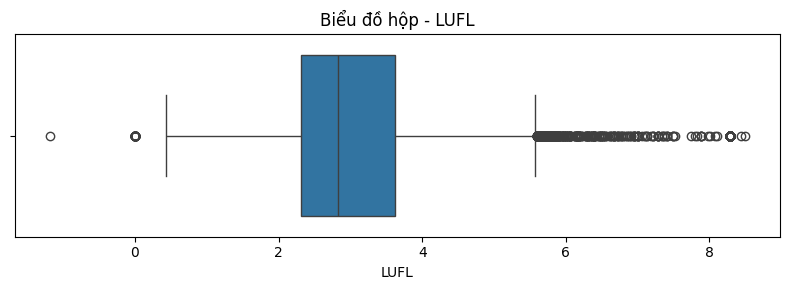

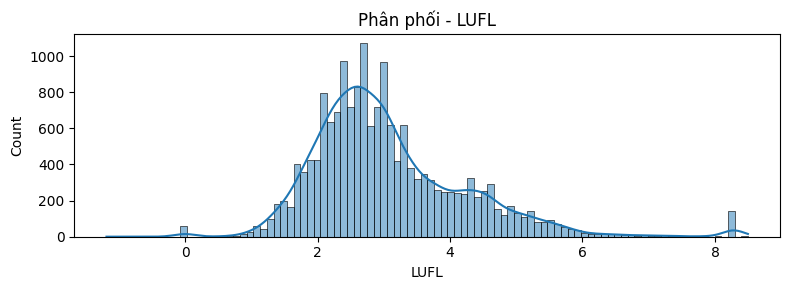

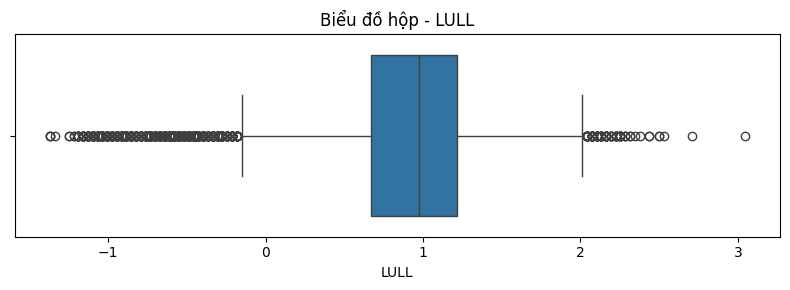

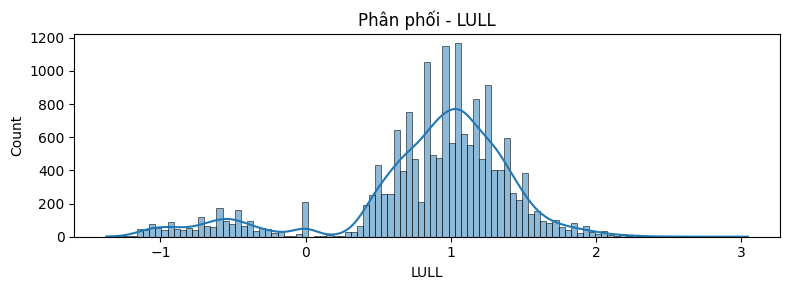

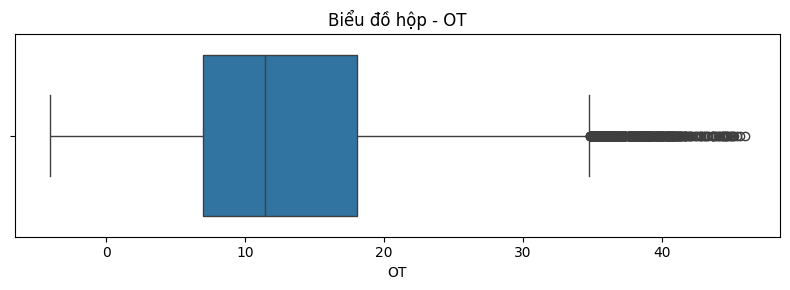

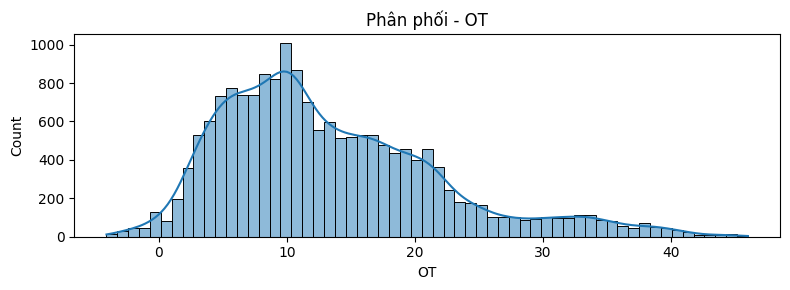

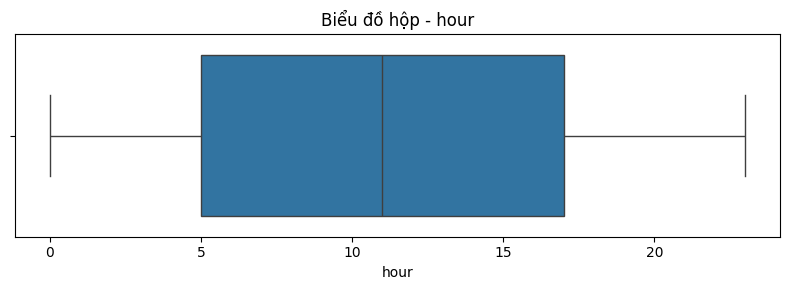

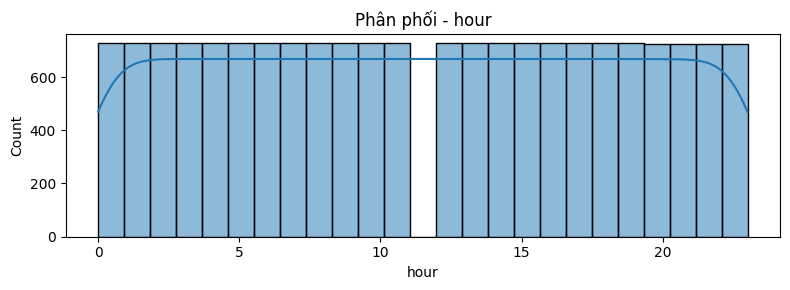

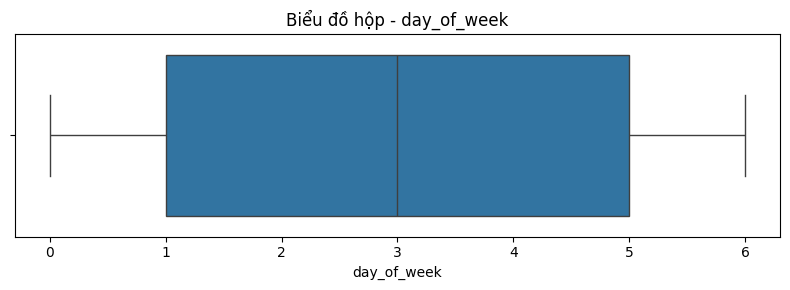

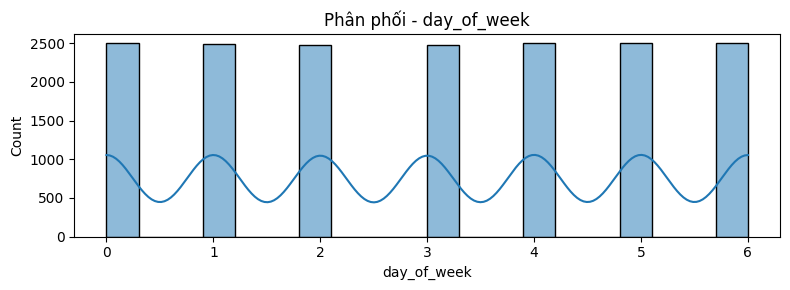

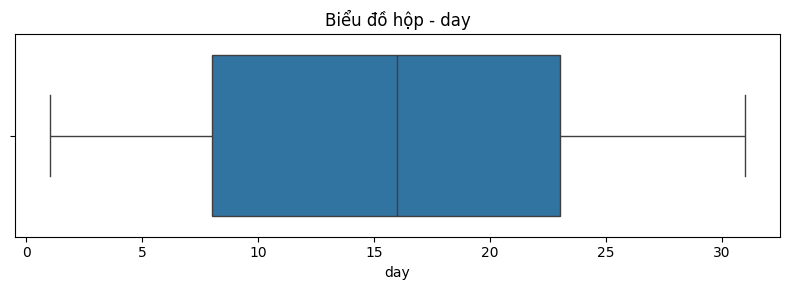

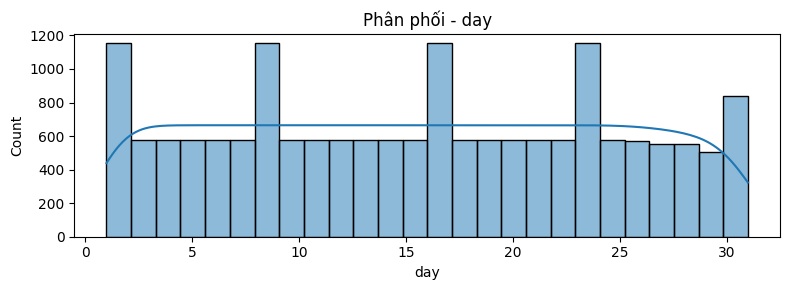

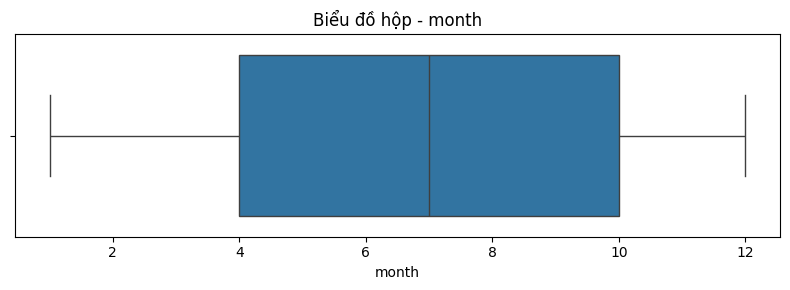

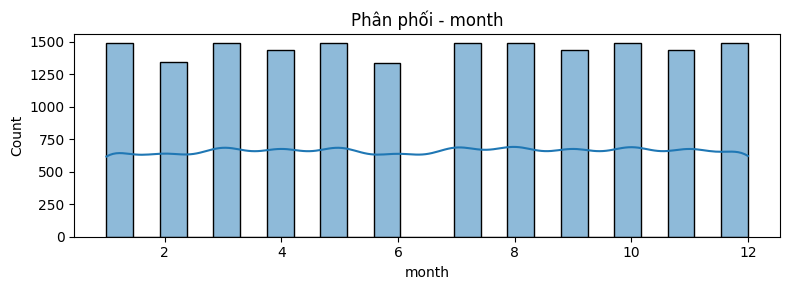

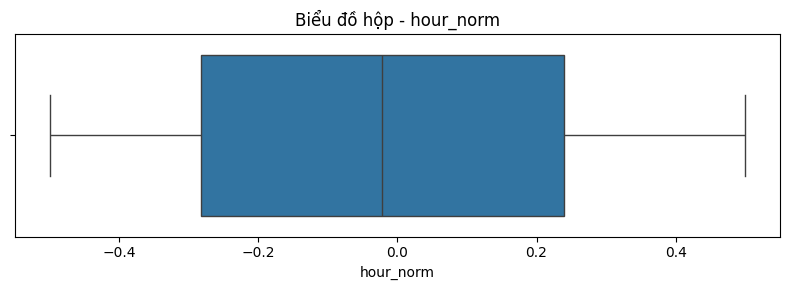

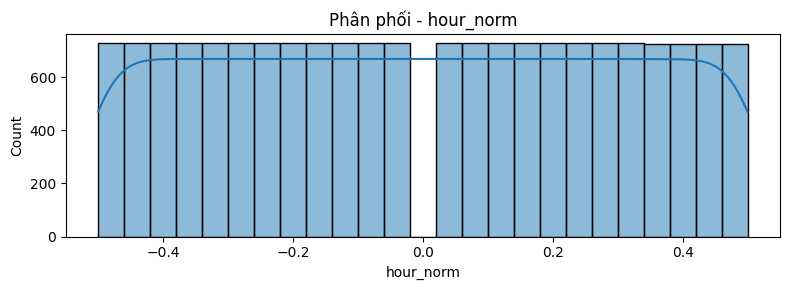

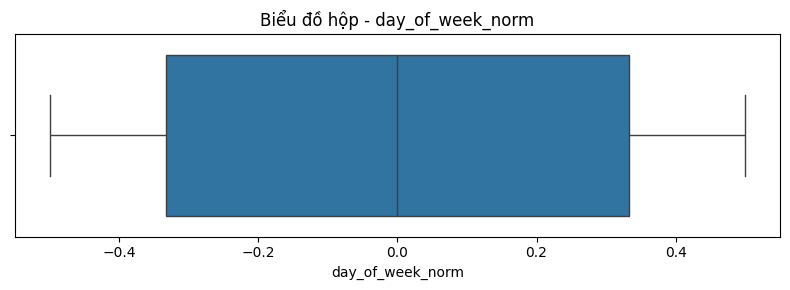

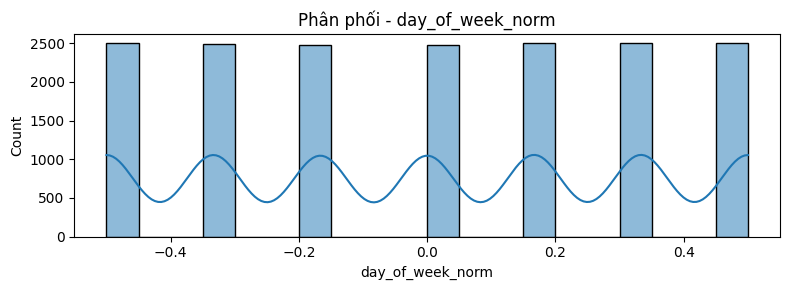

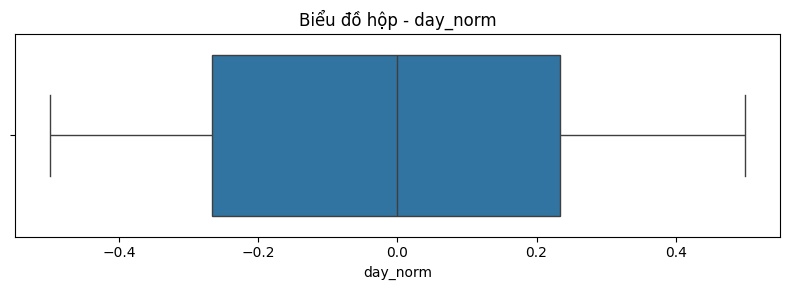

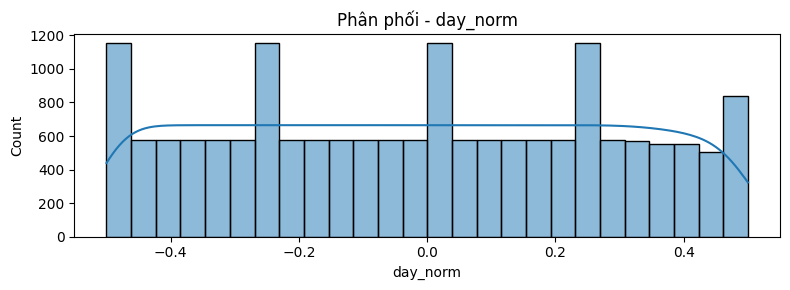

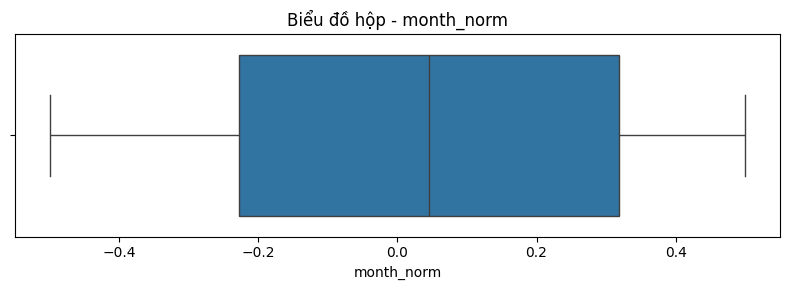

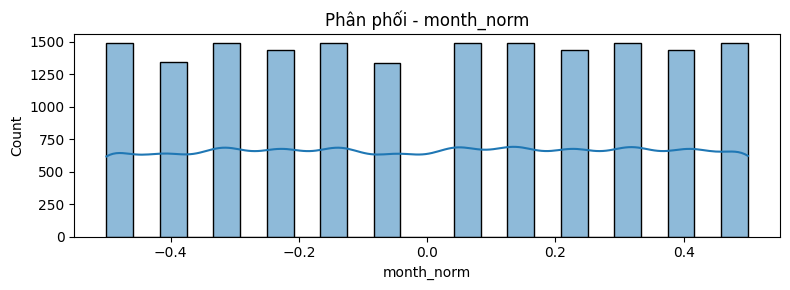

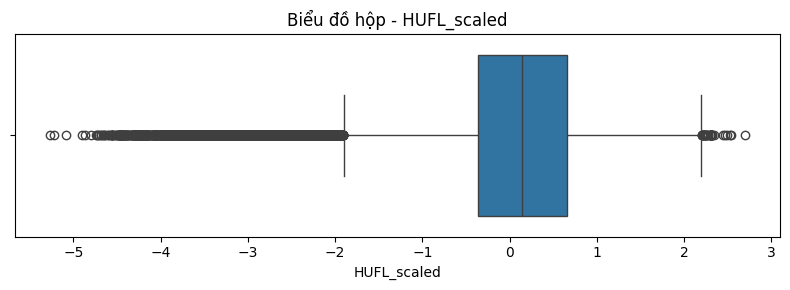

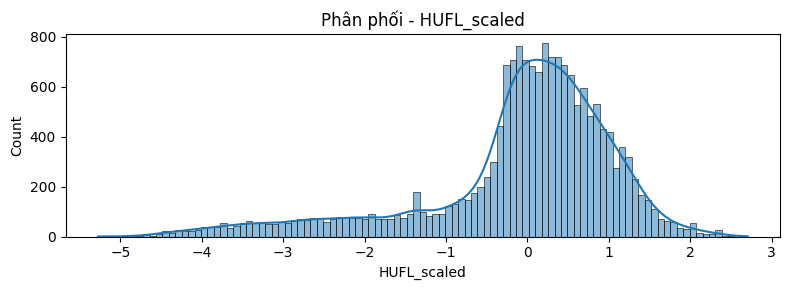

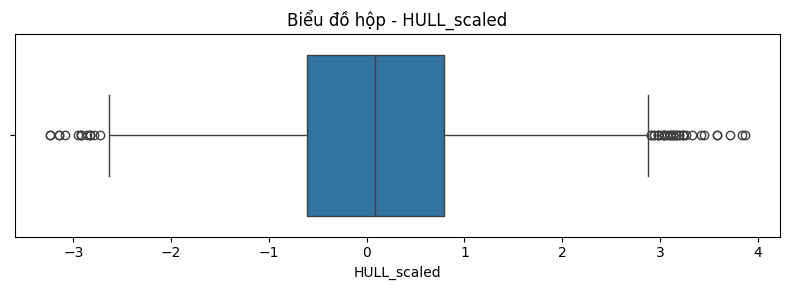

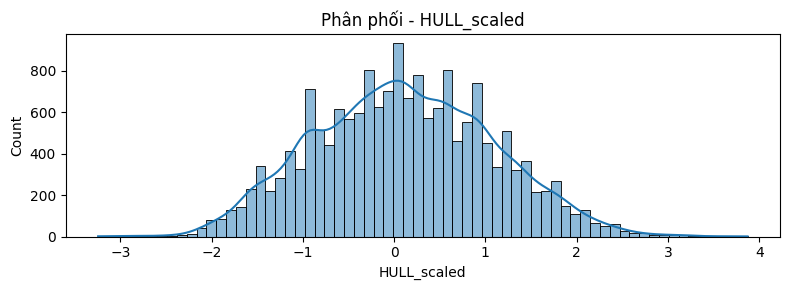

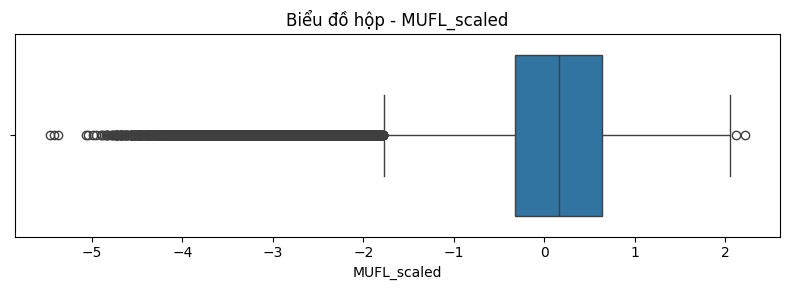

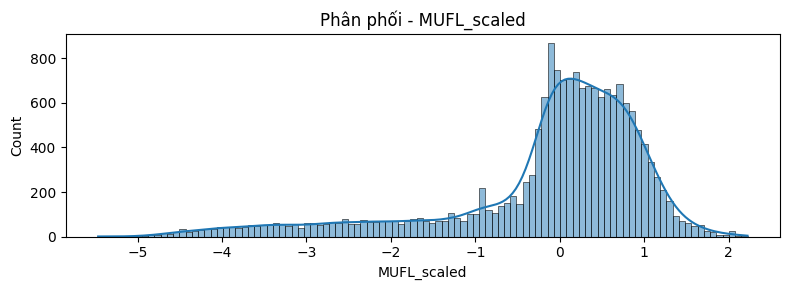

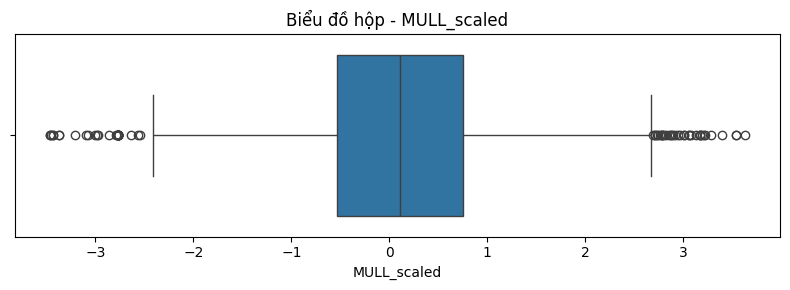

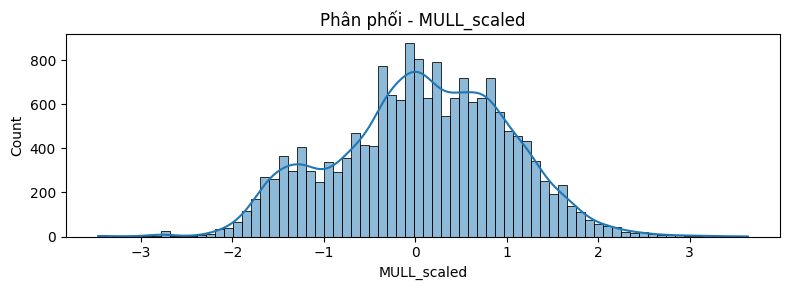

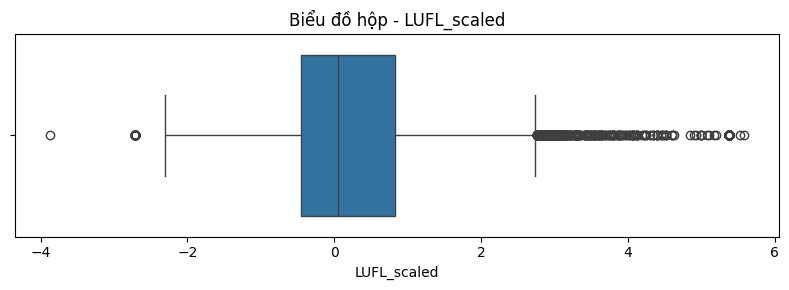

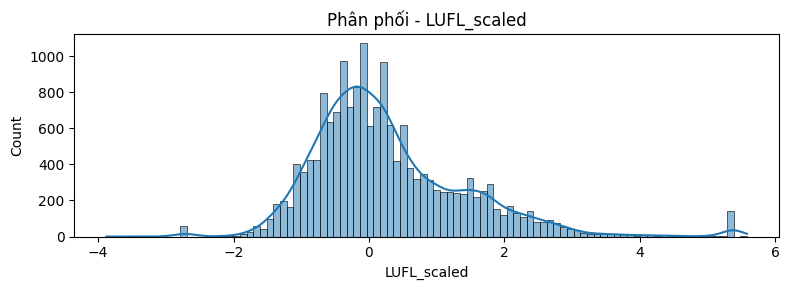

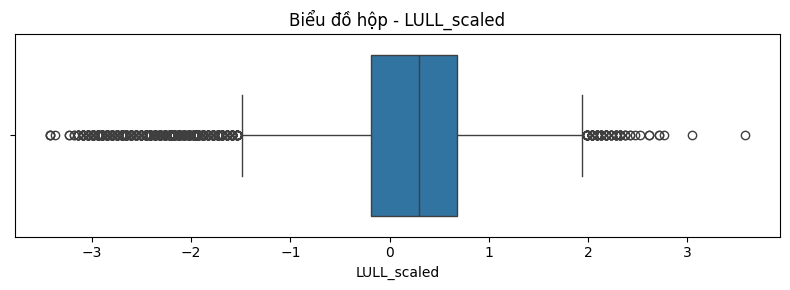

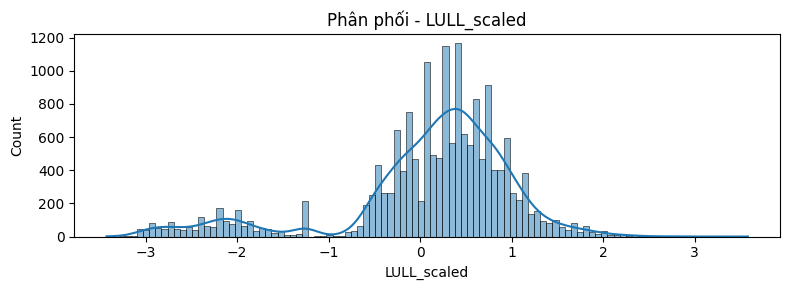

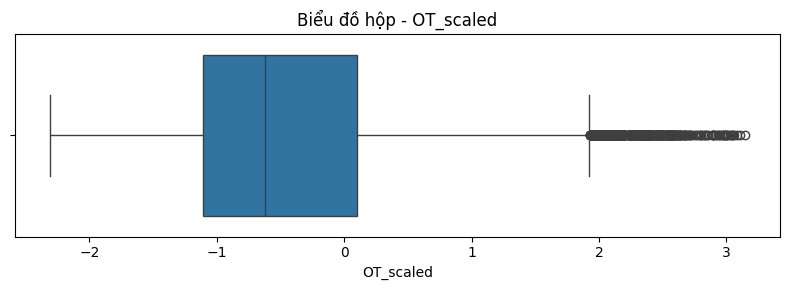

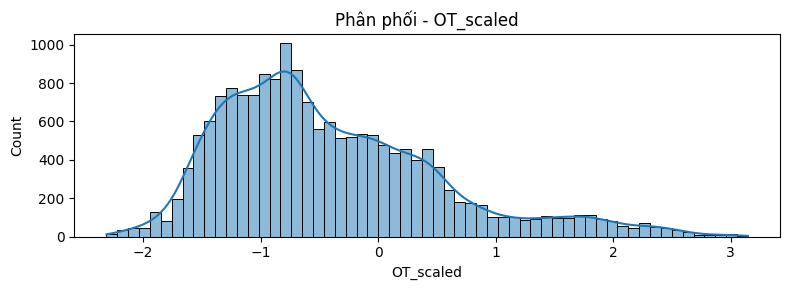


Báo cáo ngoại lệ:
          Thuoc_tinh  So_ngoai_le_IQR  Ty_le_ngoai_le_IQR_%  So_ngoai_le_3SD  \
0               HUFL             1824                 10.47              297   
1               HULL               51                  0.29               41   
2               MUFL             2005                 11.51              366   
3               MULL               78                  0.45               61   
4               LUFL              561                  3.22              219   
5               LULL             1714                  9.84              323   
6                 OT              471                  2.70              159   
7               hour                0                  0.00                0   
8        day_of_week                0                  0.00                0   
9                day                0                  0.00                0   
10             month                0                  0.00                0   
11         hour_norm 

In [ ]:
# =========================
# 6. PHÁT HIỆN NGOẠI LỆ
# =========================
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
outlier_summary = []

for col in numeric_cols:
    s = df[col].dropna()

    if s.empty:
        continue

    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_mask = (df[col] < lower) | (df[col] > upper)

    mean = s.mean()
    std = s.std()

    std_mask = (
        (df[col] < mean - 3 * std) |
        (df[col] > mean + 3 * std)
    )

    outlier_summary.append({
        "Thuoc_tinh": col,
        "So_ngoai_le_IQR": int(iqr_mask.sum()),
        "Ty_le_ngoai_le_IQR_%": round(iqr_mask.mean() * 100, 2),
        "So_ngoai_le_3SD": int(std_mask.sum()),
        "Can_duoi_IQR": lower,
        "Can_tren_IQR": upper
    })

    # Biểu đồ hộp
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Biểu đồ hộp - {col}")
    plt.tight_layout()
    plt.show()
    plt.savefig(OUTPUT_DIR / f"boxplot_{col}.png", dpi=150)
    plt.close()

    # Biểu đồ phân phối
    plt.figure(figsize=(8, 3))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Phân phối - {col}")
    plt.tight_layout()
    plt.show()
    plt.savefig(OUTPUT_DIR / f"distribution_{col}.png", dpi=150)
    plt.close()

outlier_df = pd.DataFrame(outlier_summary)

#outlier_df.to_csv(
#    OUTPUT_DIR / "outlier_report.csv",
#    index=False,
#    encoding="utf-8-sig"
#) Lưu tệp csv về báo cáo ngoại lệ 

print("\nBáo cáo ngoại lệ:")
print(outlier_df)

In [8]:
# =========================
# 7. XỬ LÝ GIÁ TRỊ THIẾU TRÊN BẢN COPY
# =========================
# Không thay đổi DataFrame df gốc sau khi tạo bản sao.
# Cột thiếu trên 60% được giữ lại để đánh giá thêm.

df_clean = df.copy(deep=True)

MISSING_THRESHOLD = 0.60
DROP_MISSING_COLUMNS = []

for col in DROP_MISSING_COLUMNS:
    if col in df_clean.columns:
        df_clean.drop(columns=col, inplace=True)
        record("Xóa cột", f"{col}: đã xác nhận cần loại bỏ")

for col in df_clean.columns:
    if df_clean[col].isna().sum() == 0:
        continue

    missing_count = int(df_clean[col].isna().sum())

    if df_clean[col].isna().mean() > MISSING_THRESHOLD:
        record(
            "Chưa xử lý cột thiếu nhiều",
            f"{col}: cần đánh giá trước khi loại bỏ",
            missing_count
        )
        continue

    if pd.api.types.is_numeric_dtype(df_clean[col]):
        fill_value = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(fill_value)

        record(
            "Điền trung vị",
            f"{col}: trung vị = {fill_value}",
            missing_count
        )

    elif pd.api.types.is_datetime64_any_dtype(df_clean[col]):
        record(
            "Giữ dữ liệu thiếu",
            f"{col}: cần xác định cách xử lý ngày giờ",
            missing_count
        )

    else:
        mode = df_clean[col].mode(dropna=True)

        if not mode.empty:
            df_clean[col] = df_clean[col].fillna(mode.iloc[0])

            record(
                "Điền giá trị phổ biến",
                f"{col}: giá trị = {mode.iloc[0]}",
                missing_count
            )
        else:
            df_clean[col] = df_clean[col].fillna("Không xác định")

            record(
                "Bổ sung nhãn",
                f"{col}: Không xác định",
                missing_count
            )

In [9]:
# =========================
# 8. XỬ LÝ TRÙNG LẶP TRÊN BẢN COPY
# =========================
duplicates_before = int(df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates(keep="first").copy()

record(
    "Xử lý trùng lặp",
    "Giữ bản ghi đầu tiên",
    duplicates_before
)

print("\nDữ liệu sau xử lý thiếu và trùng lặp:")
print("Kích thước:", df_clean.shape)
print("Giá trị thiếu:", df_clean.isna().sum().sum())
print("Dòng trùng lặp:", df_clean.duplicated().sum())



Dữ liệu sau xử lý thiếu và trùng lặp:
Kích thước: (17420, 24)
Giá trị thiếu: 0
Dòng trùng lặp: 0


In [10]:
# =========================
# 9. CHỌN LỌC THUỘC TÍNH - TẠO DATAFRAME SUBSET
# =========================
selected_columns = [
    "date", "HUFL", "HULL", "MUFL","MULL", "LUFL", "LULL", "OT",
    'hour','day_of_week','day','month',
    'HUFL_scaled','HULL_scaled','MUFL_scaled','MULL_scaled','LUFL_scaled','LULL_scaled','OT_scaled'
]

missing_columns = [
    col for col in selected_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Không tìm thấy các cột: {missing_columns}")

# Tạo subset từ dữ liệu gốc đã đọc và chuẩn hóa tên cột
df_subset = df_clean[selected_columns].copy()

print("\nDataFrame subset:")
print("Kích thước:", df_subset.shape)
display(df_subset.head())

record(
    "Chọn lọc thuộc tính",
    f"Các cột được giữ lại: {selected_columns}"
)


DataFrame subset:
Kích thước: (17420, 19)


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT,hour,day_of_week,day,month,HUFL_scaled,HULL_scaled,MUFL_scaled,MULL_scaled,LUFL_scaled,LULL_scaled,OT_scaled
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000,0,4,1,7,-0.363123,-0.005760,-0.630712,-0.147523,1.388575,0.875143,1.460552
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001,1,4,1,7,-0.386176,0.026296,-0.650101,-0.166211,1.328977,0.924330,1.161527
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001,2,4,1,7,-0.478387,-0.133983,-0.688696,-0.203068,0.972365,0.681565,1.161527
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001,3,4,1,7,-0.489913,-0.037816,-0.688696,-0.184380,1.001675,0.778354,0.862611
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000,4,4,1,7,-0.443808,-0.037816,-0.650101,-0.147523,1.061274,0.778354,0.525227


In [ ]:
# =========================
# 10. LƯU DATAFRAME SUBSET SAU EDA
# =========================
PREPROCESS_DIR.mkdir(parents=True, exist_ok=True)

#df_subset.to_csv(
#    PREPROCESS_DIR / "eda_dataset.csv",
#    index=False,
#    encoding="utf-8-sig"
#) Lưu tệp cvs về datadframe subset sau khi chọn thuộc tính 

print(
    "Đã lưu bộ dữ liệu subset tại:",
    PREPROCESS_DIR / "eda_dataset.csv"
)



Đã lưu bộ dữ liệu subset tại: preprocess data\eda_dataset.csv


In [ ]:
# =========================
# 11. KIỂM ĐỊNH, SO SÁNH VÀ LƯU KẾT QUẢ
# =========================

# Tạo bản copy của subset để xử lý thiếu và trùng lặp
df_clean = df_subset.copy(deep=True)

missing_before = int(df_clean.isna().sum().sum())
duplicates_before = int(df_clean.duplicated().sum())
rows_before = len(df_clean)

# Xử lý thiếu trên bản copy
for col in df_clean.columns:
    if df_clean[col].isna().sum() == 0:
        continue

    if pd.api.types.is_numeric_dtype(df_clean[col]):
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

    elif not pd.api.types.is_datetime64_any_dtype(df_clean[col]):
        mode = df_clean[col].mode(dropna=True)

        if not mode.empty:
            df_clean[col] = df_clean[col].fillna(mode.iloc[0])
        else:
            df_clean[col] = df_clean[col].fillna("Không xác định")

# Xử lý trùng lặp trên bản copy
df_clean = df_clean.drop_duplicates(keep="first").copy()

# Kiểm tra sau xử lý
print("\n===== SO SÁNH TRƯỚC VÀ SAU =====")
print("Số dòng trước xử lý:", rows_before)
print("Số dòng sau xử lý:", len(df_clean))
print("Giá trị thiếu trước xử lý:", missing_before)
print("Giá trị thiếu sau xử lý:", int(df_clean.isna().sum().sum()))
print("Dòng trùng trước xử lý:", duplicates_before)
print("Dòng trùng sau xử lý:", int(df_clean.duplicated().sum()))

comparison = pd.DataFrame({
    "Truoc_xu_ly": [
        rows_before,
        len(df_subset.columns),
        missing_before,
        duplicates_before
    ],
    "Sau_xu_ly": [
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.isna().sum().sum()),
        int(df_clean.duplicated().sum())
    ]
}, index=[
    "So_dong",
    "So_cot",
    "Tong_gia_tri_thieu",
    "So_dong_trung_lap"
])

#comparison.to_csv(
#    PREPROCESS_DIR / "before_after.csv",
#    encoding="utf-8-sig"
#) Lưu tệp CSV về so sánh trước và sau 

# Lưu dữ liệu đã làm sạch thành tệp riêng
df_clean.to_csv(
    PREPROCESS_DIR / "cleaned_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

# Lưu nhật ký xử lý
pd.DataFrame(log).to_csv(
    PREPROCESS_DIR / "cleaning_log.csv",
    index=False,
    encoding="utf-8-sig"
)

# Kiểm tra chất lượng sau làm sạch
quality_after = pd.DataFrame({
    "Kieu_du_lieu": df_clean.dtypes.astype(str),
    "So_luong_thieu": df_clean.isna().sum(),
    "Ty_le_thieu_%": (df_clean.isna().mean() * 100).round(2),
    "So_gia_tri_khac_nhau": df_clean.nunique(dropna=True)
})

quality_after.to_csv(
    PREPROCESS_DIR / "quality_after.csv",
    encoding="utf-8-sig"
)

print("\nHoàn tất.")
print("Dữ liệu gốc vẫn được giữ trong biến df.")
print("Dữ liệu subset:", PREPROCESS_DIR / "eda_dataset.csv")
print("Dữ liệu đã làm sạch:", PREPROCESS_DIR / "cleaned_dataset.csv")


===== SO SÁNH TRƯỚC VÀ SAU =====
Số dòng trước xử lý: 17420
Số dòng sau xử lý: 17420
Giá trị thiếu trước xử lý: 0
Giá trị thiếu sau xử lý: 0
Dòng trùng trước xử lý: 0
Dòng trùng sau xử lý: 0

Hoàn tất.
Dữ liệu gốc vẫn được giữ trong biến df.
Dữ liệu subset: preprocess data\eda_dataset.csv
Dữ liệu đã làm sạch: preprocess data\cleaned_dataset.csv


Tổng có 17420 dòng và 24 đặc trưng 